# DSCI 552: HW6
- **Name:** Pavanitha Manche
- **USC ID:** 2866839249
- **GitHub Username:** Pavanitha09

In [28]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

## 1. Tree-Based Methods

### 1(a) Data Loading

In [29]:
data_path = '../data/'
train_raw = pd.read_csv(data_path + 'aps_failure_training_set.csv', skiprows=20, na_values='na')
test_raw = pd.read_csv(data_path + 'aps_failure_test_set.csv', skiprows=20, na_values='na')

FEATS = [c for c in train_raw.columns if c != 'class']
y_train = (train_raw['class'] == 'pos').astype(int)
y_test = (test_raw['class'] == 'pos').astype(int)

print(f'Training set: {train_raw.shape}, test set: {test_raw.shape}')
display(train_raw.iloc[:5, :10])

Training set: (60000, 171), test set: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0


### 1(b)(i) Missing Values: Imputation

* **Techniques:** deletion, mean/median/mode imputation, KNN imputation, regression/MICE imputation, missing-indicator features.
* **Used:** median imputation (training set with training medians, test set with test medians).

In [30]:
miss = train_raw[FEATS].isna().mean()
print(f'Rows with at least one missing value: {train_raw[FEATS].isna().any(axis=1).mean():.1%}')
print(f'Features with missing values: {(miss > 0).sum()} of {len(FEATS)}, largest missing fraction = {miss.max():.1%}')

X_train = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(train_raw[FEATS]), columns=FEATS)
X_test = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(test_raw[FEATS]), columns=FEATS)
X_all = pd.concat([X_train, X_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)

Rows with at least one missing value: 99.0%
Features with missing values: 169 of 170, largest missing fraction = 82.1%


* 99% of rows have a missing value, so deleting them is not an option.

### 1(b)(ii) Coefficient of Variation

In [31]:
cv_feat = (X_all.std(ddof=1) / X_all.mean()).sort_values(ascending=False)
blocks = [cv_feat.iloc[i:i + 34].round(2).reset_index().set_axis(['Feature', 'CV'], axis=1)
          for i in range(0, len(cv_feat), 34)]
display(pd.concat(blocks, axis=1))

,Feature,CV,Feature,CV,Feature,CV,Feature,CV,Feature,CV
0,cf_000,275.60,ay_003,28.66,cn_002,6.84,ee_001,3.26,bb_000,2.42
1,co_000,275.07,cn_000,28.30,ba_008,6.78,cs_003,3.20,bu_000,2.42
2,ad_000,274.79,at_000,23.43,be_000,6.60,dd_000,3.11,cq_000,2.42
3,cs_009,194.72,ae_000,23.27,cu_000,6.48,ap_000,3.11,bv_000,2.42
4,dj_000,130.92,az_008,22.67,bz_000,6.35,az_005,3.09,ed_000,2.42
5,dh_000,120.76,dq_000,22.21,ag_008,6.34,cn_006,3.08,ci_000,2.40
6,df_000,119.38,af_000,19.01,cn_007,6.17,ck_000,3.06,ag_006,2.36
7,as_000,115.08,ai_000,18.70,av_000,5.96,ay_006,3.05,cn_005,2.35
8,ag_000,92.51,ag_002,17.83,ee_009,5.82,bi_000,3.03,ds_000,2.34
9,au_000,86.99,az_007,15.56,db_000,5.70,ba_006,3.02,ah_000,2.33


### 1(b)(iii) Correlation Matrix

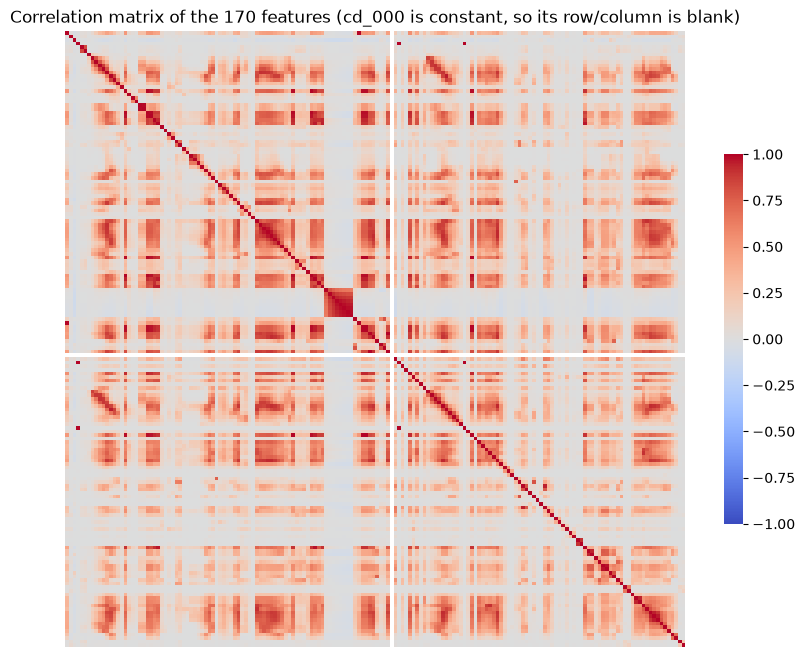

In [32]:
plt.figure(figsize=(10, 8))
sns.heatmap(X_all.corr(), cmap='coolwarm', vmin=-1, vmax=1, xticklabels=False, yticklabels=False,
            cbar_kws={'shrink': 0.6})
plt.title('Correlation matrix of the 170 features (cd_000 is constant, so its row/column is blank)')
plt.show()

### 1(b)(iv) Scatter Plots and Box Plots for the ⌊√170⌋ Highest-CV Features

13 highest-CV features: cf_000, co_000, ad_000, cs_009, dj_000, dh_000, df_000, as_000, ag_000, au_000, ak_000, az_009, ay_009


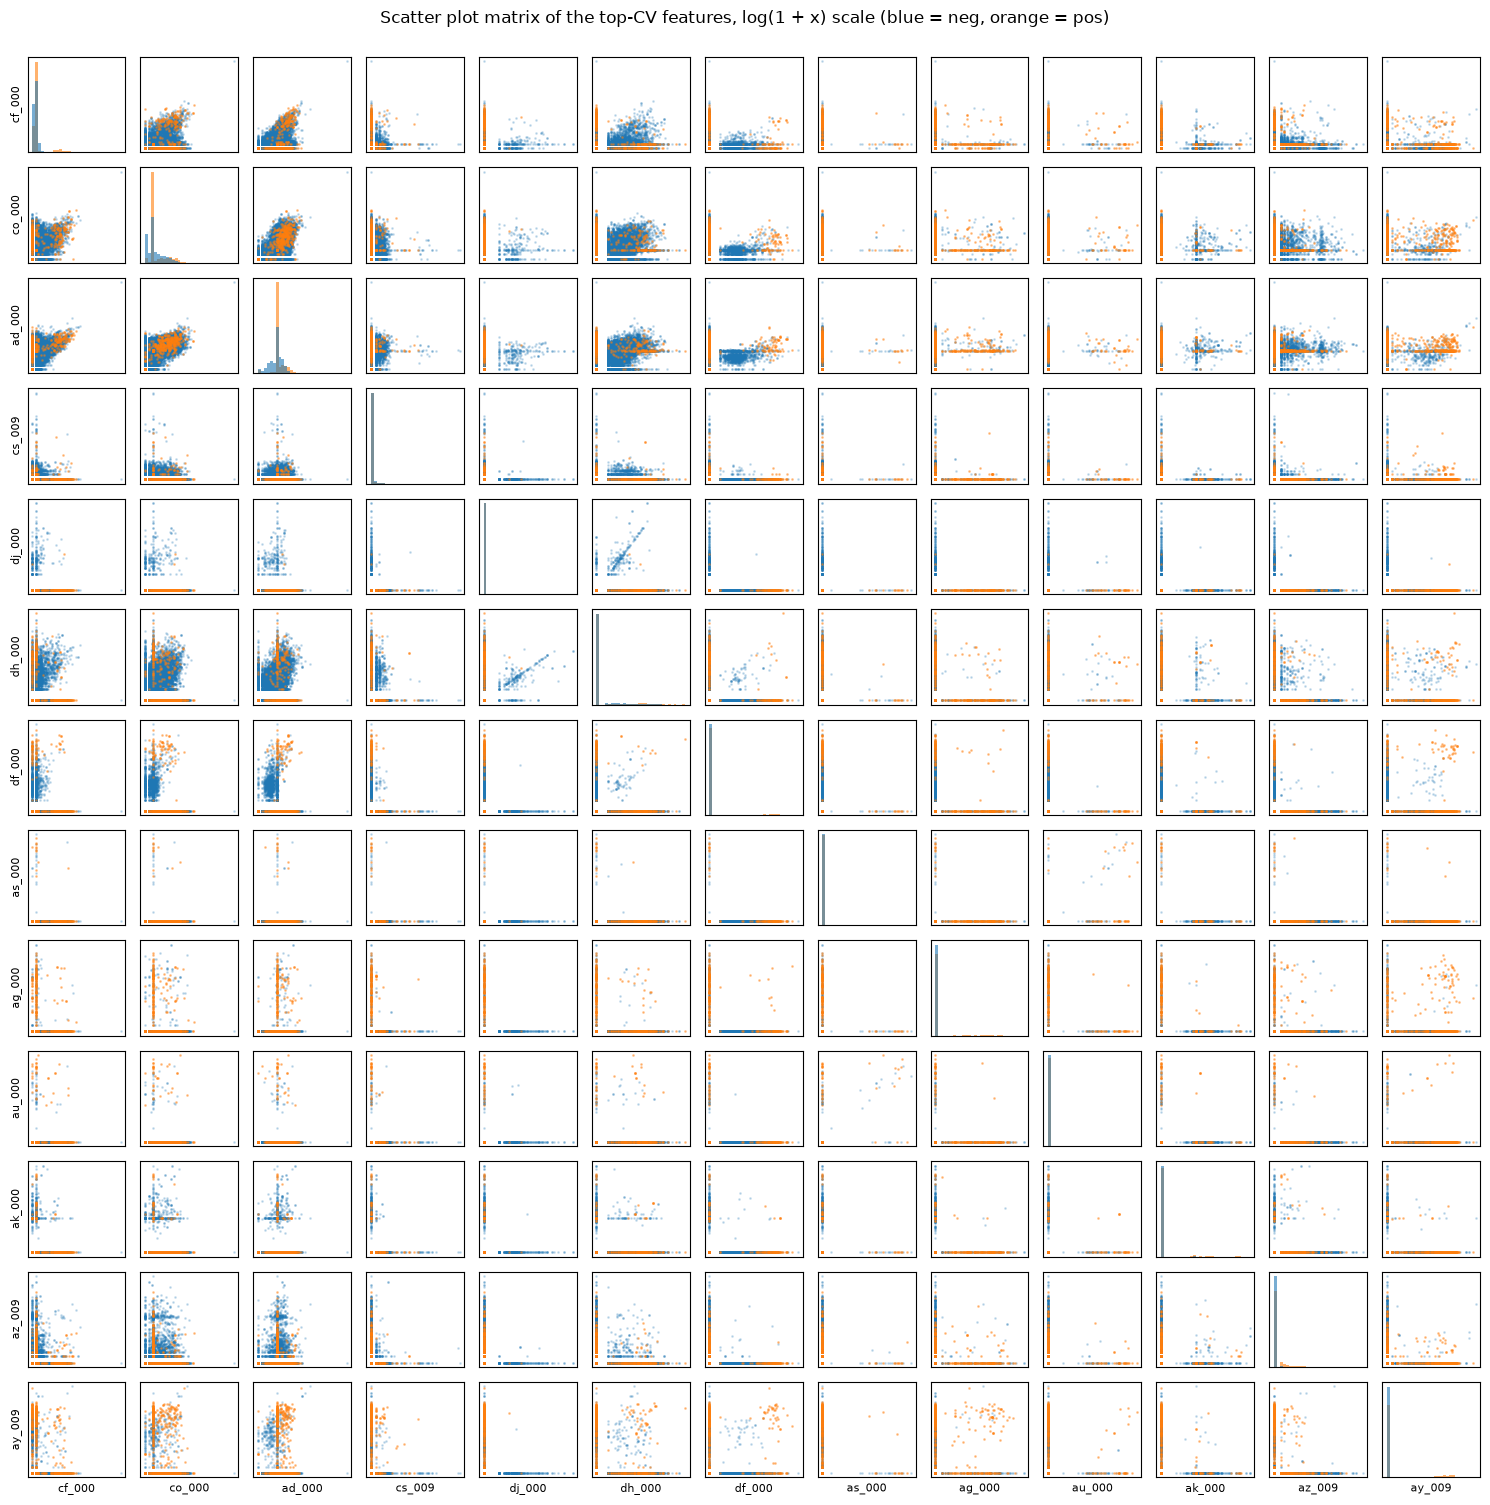

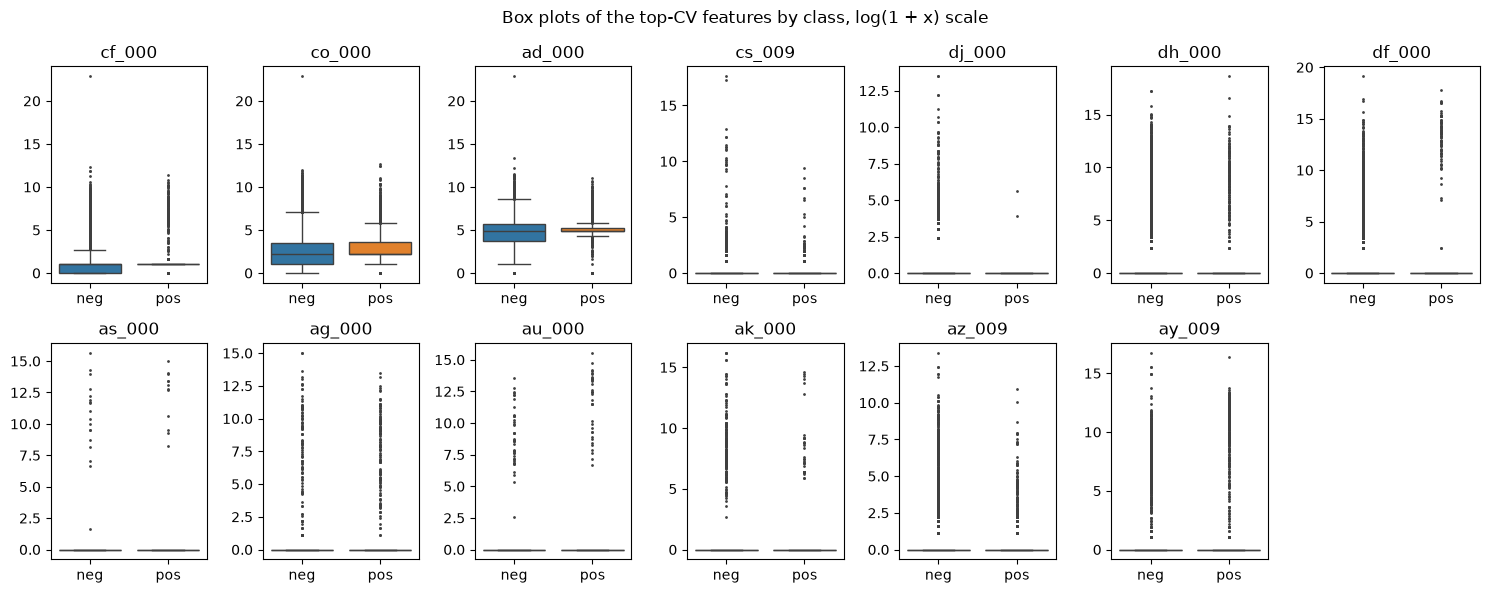

In [33]:
top = list(cv_feat.index[:int(np.floor(np.sqrt(170)))])
print(f'{len(top)} highest-CV features:', ', '.join(top))

# The features are heavily skewed, so they are plotted on a log(1 + x) scale for readability
viz = np.log1p(X_all[top])
neg, pos = y_all == 0, y_all == 1
k = len(top)
fig, axes = plt.subplots(k, k, figsize=(15, 15))
for i, fi in enumerate(top):
    for j, fj in enumerate(top):
        ax = axes[i, j]
        if i == j:
            ax.hist([viz.loc[neg, fi], viz.loc[pos, fi]], bins=30, density=True, histtype='stepfilled',
                    color=['tab:blue', 'tab:orange'], alpha=0.6)
        else:
            ax.scatter(viz.loc[neg, fj], viz.loc[neg, fi], s=1, alpha=0.2, c='tab:blue', rasterized=True)
            ax.scatter(viz.loc[pos, fj], viz.loc[pos, fi], s=1, alpha=0.4, c='tab:orange', rasterized=True)
        ax.set_xticks([])
        ax.set_yticks([])
        if i == k - 1:
            ax.set_xlabel(fj, fontsize=8)
        if j == 0:
            ax.set_ylabel(fi, fontsize=8)
fig.suptitle('Scatter plot matrix of the top-CV features, log(1 + x) scale (blue = neg, orange = pos)', y=1.0)
plt.tight_layout()
plt.show()

cls = y_all.map({0: 'neg', 1: 'pos'})
fig, axes = plt.subplots(2, 7, figsize=(15, 6))
for ax, col in zip(axes.flat, top):
    sns.boxplot(x=cls, y=viz[col], hue=cls, palette=['tab:blue', 'tab:orange'], legend=False,
                fliersize=1, ax=ax)
    ax.set(title=col, xlabel='', ylabel='')
axes.flat[-1].axis('off')
fig.suptitle('Box plots of the top-CV features by class, log(1 + x) scale')
plt.tight_layout()
plt.show()

* **No.** Some features shift between classes in the box plots (e.g. `cf_000`, `co_000`, `ad_000`), but the classes overlap heavily. Significance needs a fitted model and a statistical test.

### 1(b)(v) Class Balance

In [34]:
counts = pd.DataFrame({'Training': y_train.value_counts(), 'Test': y_test.value_counts()})
counts.index = counts.index.map({0: 'neg', 1: 'pos'})
counts.loc['% pos'] = (100 * counts.loc['pos'] / counts.sum()).round(2)
display(counts)

,Training,Test
class,,
neg,59000.00,15625.00
pos,1000.00,375.00
% pos,1.67,2.34


* **Yes, highly imbalanced:** training 1,000 pos vs. 59,000 neg (1.67% pos); test 375 vs. 15,625 (2.34% pos).

### 1(c) Random Forest (No Class-Imbalance Compensation)

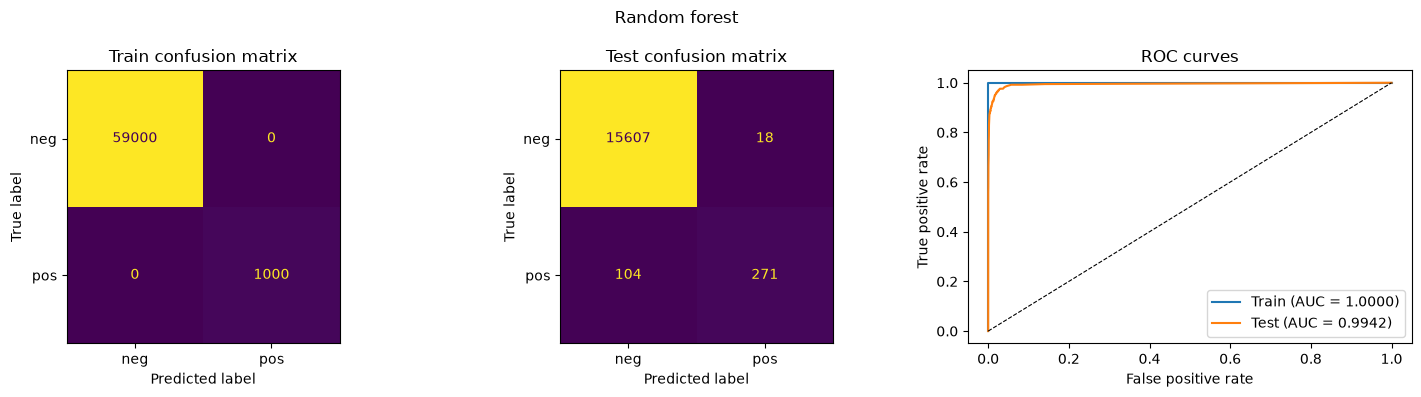

,Train AUC,Train misclassification,Test AUC,Test misclassification,OOB / CV error
Random forest,1.0,0.0,0.9942,0.0076,0.0058


OOB error = 0.0058, test error = 0.0076


In [35]:
results = {}

def evaluate(model, name, extra=None):
    """Confusion matrices (train/test), ROC curves, AUC and misclassification rate."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    row = {}
    for ax, (split, X, y) in zip(axes[:2], [('Train', X_train, y_train), ('Test', X_test, y_test)]):
        prob = model.predict_proba(X)[:, 1]
        pred = model.predict(X)
        ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=['neg', 'pos']).plot(
            ax=ax, colorbar=False, values_format='d')
        ax.set_title(f'{split} confusion matrix')
        fpr, tpr, _ = roc_curve(y, prob)
        row[f'{split} AUC'] = roc_auc_score(y, prob)
        row[f'{split} misclassification'] = (pred != y).mean()
        axes[2].plot(fpr, tpr, label=f'{split} (AUC = {row[f"{split} AUC"]:.4f})')
    axes[2].plot([0, 1], [0, 1], 'k--', lw=0.8)
    axes[2].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves')
    axes[2].legend(loc='lower right')
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()
    row.update(extra or {})
    results[name] = row
    display(pd.DataFrame(row, index=[name]).round(4))

rf = RandomForestClassifier(n_estimators=300, oob_score=True, n_jobs=-1, random_state=42).fit(X_train, y_train)
evaluate(rf, 'Random forest', {'OOB / CV error': 1 - rf.oob_score_})
print(f'OOB error = {1 - rf.oob_score_:.4f}, test error = {results["Random forest"]["Test misclassification"]:.4f}')

* OOB error (0.58%) is close to the test error (0.76%).
* Training error is 0, but 104 of the 375 positive test trucks are missed.

### 1(d) Random Forest with Class-Imbalance Compensation

* **Methods:** class weights (cost-sensitive RF), Balanced RF (majority class down-sampled in each bootstrap sample), over/under-sampling (e.g. SMOTE), threshold moving.
* **Used:** Balanced RF.

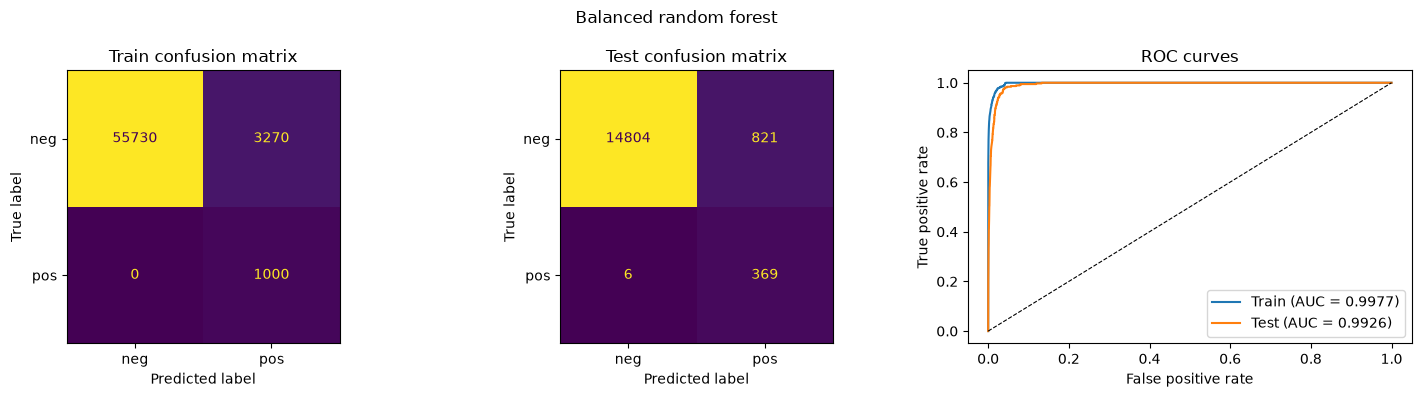

,Train AUC,Train misclassification,Test AUC,Test misclassification,OOB / CV error
Balanced random forest,0.9977,0.0545,0.9926,0.0517,0.0549


OOB error = 0.0549, test error = 0.0517


In [36]:
brf = BalancedRandomForestClassifier(n_estimators=1000, sampling_strategy='auto', replacement=False,
                                     bootstrap=True, oob_score=True, n_jobs=-1, random_state=42)
brf.fit(X_train, y_train)
evaluate(brf, 'Balanced random forest', {'OOB / CV error': 1 - brf.oob_score_})
print(f'OOB error = {1 - brf.oob_score_:.4f}, test error = {results["Balanced random forest"]["Test misclassification"]:.4f}')

* **vs. 1(c):** missed positives drop 104 → 6, false positives rise 18 → 821, test error rises 0.76% → 5.17%; test AUC about the same (0.9942 vs. 0.9926).
* OOB error (5.49%) is close to the test error (5.17%).

### 1(e) XGBoost Model Tree with L1-Penalized Logistic Regression (α by CV)

* Logistic loss with L1 penalty `reg_alpha` = α; α chosen by 5-fold stratified CV.

In [37]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ALPHAS = [0, 0.01, 0.1, 1, 10, 100]
XGB_PARAMS = dict(n_estimators=300, learning_rate=0.1, max_depth=6, tree_method='hist',
                  eval_metric='logloss', n_jobs=-1, random_state=42)

def tune(estimator, param):
    gs = GridSearchCV(estimator, {param: ALPHAS}, cv=skf, scoring={'auc': 'roc_auc', 'acc': 'accuracy'},
                      refit='auc').fit(X_train, y_train)
    res = gs.cv_results_
    display(pd.DataFrame({'alpha': ALPHAS, 'CV AUC': res['mean_test_auc'],
                          'CV error': 1 - res['mean_test_acc']}).set_index('alpha').T.round(5))
    cv_err = 1 - res['mean_test_acc'][gs.best_index_]
    print(f'Best alpha = {gs.best_params_[param]}, CV AUC = {gs.best_score_:.5f}, CV error = {cv_err:.5f}')
    return gs.best_estimator_, cv_err

xgb, xgb_cv_err = tune(XGBClassifier(**XGB_PARAMS), 'reg_alpha')

alpha,0.00,0.01,0.10,1.00,10.00,100.00
CV AUC,0.98900,0.98853,0.98885,0.98927,0.98929,0.98200
CV error,0.00522,0.00518,0.00540,0.00538,0.00712,0.01098


Best alpha = 10, CV AUC = 0.98929, CV error = 0.00712


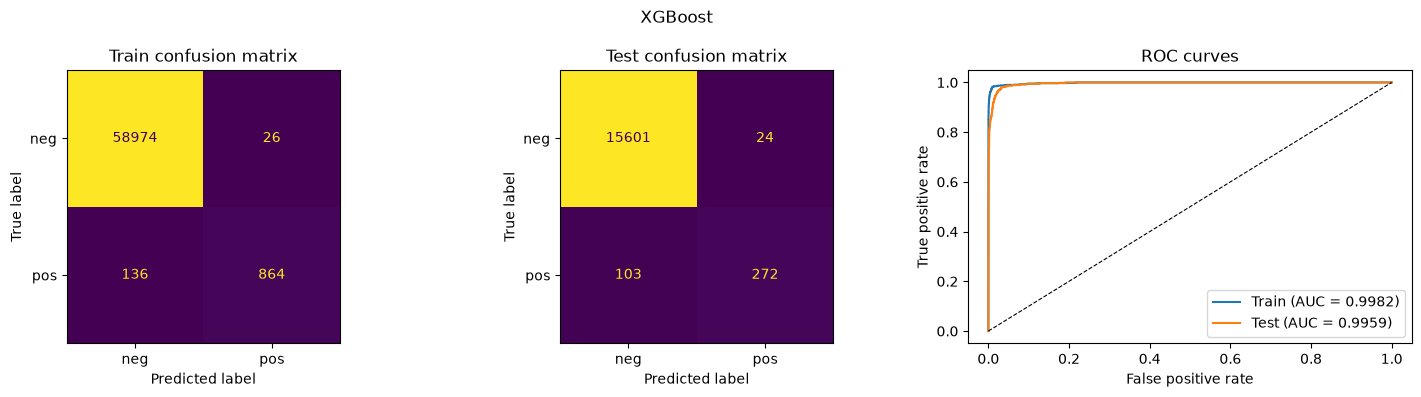

,Train AUC,Train misclassification,Test AUC,Test misclassification,OOB / CV error
XGBoost,0.9982,0.0027,0.9959,0.0079,0.0071


5-fold CV error = 0.0071, test error = 0.0079


In [38]:
evaluate(xgb, 'XGBoost', {'OOB / CV error': xgb_cv_err})
print(f'5-fold CV error = {xgb_cv_err:.4f}, test error = {results["XGBoost"]["Test misclassification"]:.4f}')

* Best α = 10. 5-fold CV error (0.71%) is close to the test error (0.79%).
* Test AUC = 0.9959; 103 of 375 positive test trucks are missed.

### 1(f) SMOTE + XGBoost (Right Way of Cross-Validation)

* **Right way:** SMOTE inside the pipeline oversamples only the training folds; validation folds keep original data. (SMOTE before CV would leak synthetic copies of validation points into training.)

In [39]:
smote_pipe = Pipeline([('scale', StandardScaler()), ('smote', SMOTE(random_state=42)),
                       ('xgb', XGBClassifier(**XGB_PARAMS))])
smote_xgb, smote_cv_err = tune(smote_pipe, 'xgb__reg_alpha')

alpha,0.00,0.01,0.10,1.00,10.00,100.00
CV AUC,0.98715,0.98724,0.98713,0.98711,0.98757,0.98618
CV error,0.00642,0.00625,0.00633,0.00635,0.00795,0.01885


Best alpha = 10, CV AUC = 0.98757, CV error = 0.00795


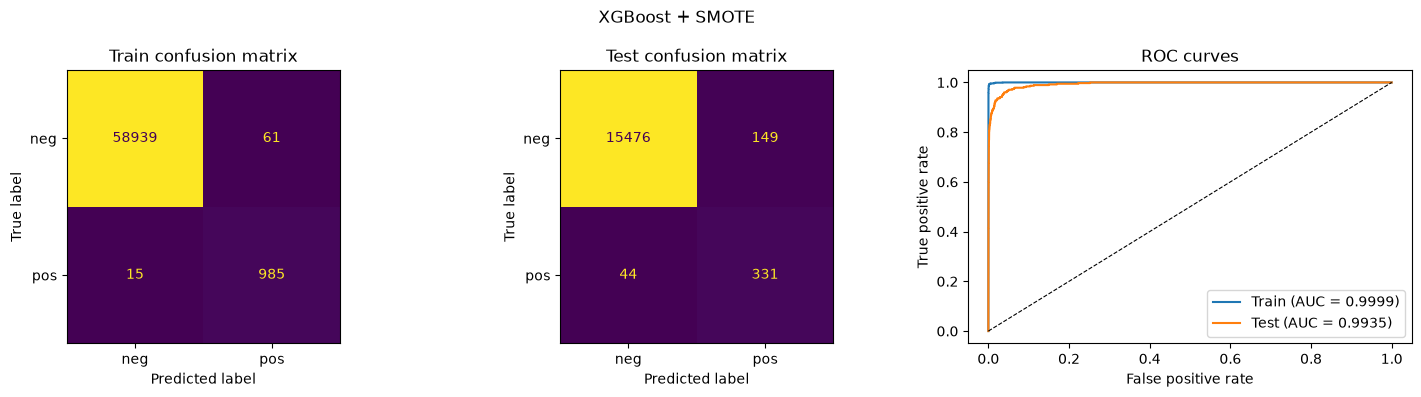

,Train AUC,Train misclassification,Test AUC,Test misclassification,OOB / CV error
XGBoost + SMOTE,0.9999,0.0013,0.9935,0.0121,0.008


5-fold CV error = 0.0080, test error = 0.0121


,Train AUC,Train misclassification,Test AUC,Test misclassification,OOB / CV error,Test FP,Test FN
Random forest,1.0000,0.0000,0.9942,0.0076,0.0058,18,104
Balanced random forest,0.9977,0.0545,0.9926,0.0517,0.0549,821,6
XGBoost,0.9982,0.0027,0.9959,0.0079,0.0071,24,103
XGBoost + SMOTE,0.9999,0.0013,0.9935,0.0121,0.0080,149,44


In [40]:
evaluate(smote_xgb, 'XGBoost + SMOTE', {'OOB / CV error': smote_cv_err})
print(f'5-fold CV error = {smote_cv_err:.4f}, test error = {results["XGBoost + SMOTE"]["Test misclassification"]:.4f}')

test_cm = {name: confusion_matrix(y_test, m.predict(X_test)).ravel()
           for name, m in [('Random forest', rf), ('Balanced random forest', brf),
                           ('XGBoost', xgb), ('XGBoost + SMOTE', smote_xgb)]}
summary = pd.DataFrame(results).T
summary['Test FP'] = [test_cm[n][1] for n in summary.index]
summary['Test FN'] = [test_cm[n][2] for n in summary.index]
display(summary.round(4))

* Best α = 10. 5-fold CV error (0.80%) is lower than the test error (1.21%).
* **SMOTE vs. uncompensated (1e):** missed positives 103 → 44, false positives 24 → 149, test error 0.79% → 1.21%, test AUC 0.9959 → 0.9935.

## 2. ISLR 6.6.3: Lasso as a Constrained Problem, Increasing $s$ from 0

* **(a) iv. Steadily decrease** (larger $s$ fits the training data more closely).
* **(b) ii. Decrease initially, then increase in a U shape** (bias falls first, then overfitting).
* **(c) iii. Steadily increase** (coefficients are less constrained).
* **(d) iv. Steadily decrease** (model becomes more flexible).
* **(e) v. Remain constant** (irreducible error does not depend on the model).

## 3. ISLR 6.6.5: Ridge vs. Lasso with Two Identical Features

With $x_{11} = x_{12} = a$, $x_{21} = x_{22} = -a$, $y_2 = -y_1$ and $\hat\beta_0 = 0$:

**(a)** $$\min_{\beta_1, \beta_2}\; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2) = \min_{\beta_1, \beta_2}\; 2\left(y_1 - a(\beta_1 + \beta_2)\right)^2 + \lambda(\beta_1^2 + \beta_2^2)$$

**(b)** Setting the partial derivatives to 0:
$$-4a\left(y_1 - a(\beta_1 + \beta_2)\right) + 2\lambda\beta_1 = 0, \qquad -4a\left(y_1 - a(\beta_1 + \beta_2)\right) + 2\lambda\beta_2 = 0$$
Subtracting: $2\lambda(\beta_1 - \beta_2) = 0 \Rightarrow \hat\beta_1 = \hat\beta_2$.

**(c)** $$\min_{\beta_1, \beta_2}\; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(|\beta_1| + |\beta_2|) = \min_{\beta_1, \beta_2}\; 2\left(y_1 - a(\beta_1 + \beta_2)\right)^2 + \lambda(|\beta_1| + |\beta_2|)$$

**(d)** If $\beta_1, \beta_2$ have the same sign, $|\beta_1| + |\beta_2| = |\beta_1 + \beta_2|$, so the objective depends only on $t = \beta_1 + \beta_2$. With $\hat t$ the optimal sum, **every pair with $\hat\beta_1 + \hat\beta_2 = \hat t$ and $\hat\beta_1, \hat\beta_2$ of the same sign is a solution**: a line segment, i.e. an edge of the lasso diamond $|\beta_1| + |\beta_2| \le s$.

## 4. ISLR 8.4.5: Majority Vote vs. Average Probability

* **Majority vote: Red** (6 of the 10 estimates are > 0.5).
* **Average probability: Green** (mean = 4.5 / 10 = 0.45 < 0.5).

## 5. ISLR 9.7.3: Maximal Margin Classifier on a Toy Data Set

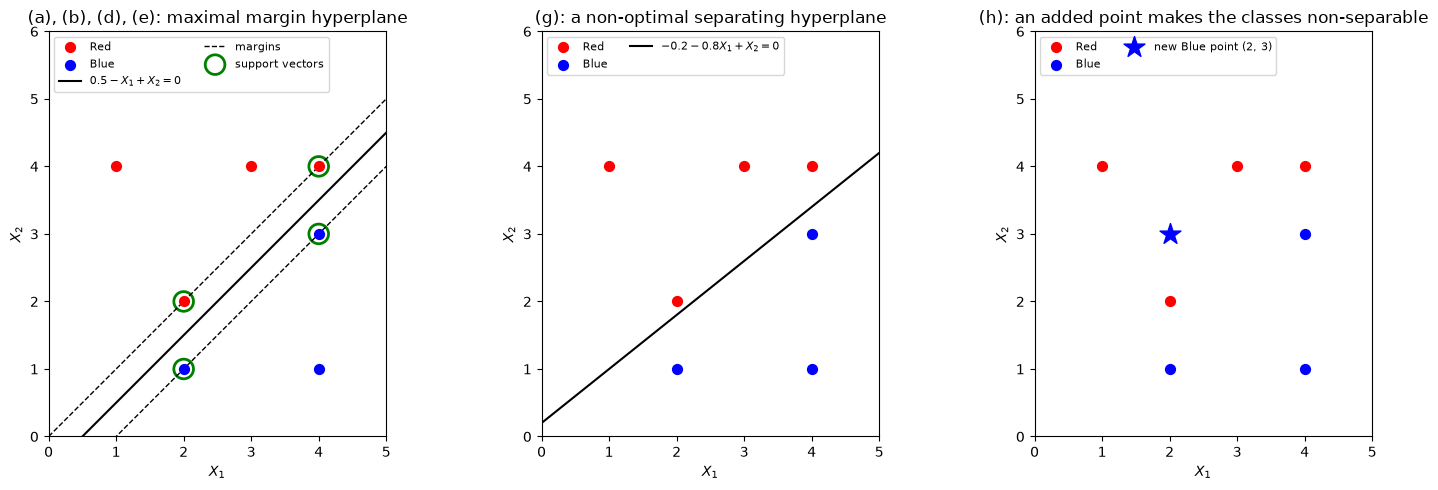

In [41]:
X1 = np.array([3, 2, 4, 1, 2, 4, 4])
X2 = np.array([4, 2, 4, 4, 1, 3, 1])
Y = np.array(['Red'] * 4 + ['Blue'] * 3)
xs = np.linspace(0, 5, 100)

def sketch(ax, title):
    for c in ['Red', 'Blue']:
        ax.scatter(X1[Y == c], X2[Y == c], c=c.lower(), s=50, label=c, zorder=3)
    ax.set(xlim=(0, 5), ylim=(0, 6), xlabel='$X_1$', ylabel='$X_2$', title=title)
    ax.set_aspect('equal')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sketch(axes[0], '(a), (b), (d), (e): maximal margin hyperplane')
axes[0].plot(xs, xs - 0.5, 'k', label='$0.5 - X_1 + X_2 = 0$')
axes[0].plot(xs, xs, 'k--', lw=1, label='margins')
axes[0].plot(xs, xs - 1, 'k--', lw=1)
sv = [1, 2, 4, 5]
axes[0].scatter(X1[sv], X2[sv], s=200, facecolors='none', edgecolors='green', lw=2, label='support vectors')
axes[0].legend(loc='upper left', fontsize=8, ncol=2)

sketch(axes[1], '(g): a non-optimal separating hyperplane')
axes[1].plot(xs, 0.8 * xs + 0.2, 'k', label='$-0.2 - 0.8X_1 + X_2 = 0$')
axes[1].legend(loc='upper left', fontsize=8, ncol=2)

sketch(axes[2], '(h): an added point makes the classes non-separable')
axes[2].scatter([2], [3], c='blue', marker='*', s=250, zorder=4, label='new Blue point (2, 3)')
axes[2].legend(loc='upper left', fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

* **(a)** Plotted above.
* **(b)** $0.5 - X_1 + X_2 = 0$ (through (2, 1.5) and (4, 3.5)).
* **(c)** Red if $0.5 - X_1 + X_2 > 0$, Blue otherwise ($\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$).
* **(d)** Margins: $X_2 = X_1$ and $X_2 = X_1 - 1$ (dashed); margin $= 0.5/\sqrt{2} \approx 0.354$.
* **(e)** Support vectors: (2, 2), (4, 4), (2, 1), (4, 3).
* **(f)** (4, 1) is not a support vector, so a slight move does not change the hyperplane.
* **(g)** $-0.2 - 0.8X_1 + X_2 = 0$.
* **(h)** Adding a Blue point at (2, 3) makes the classes non-separable.